In [1]:
import geopandas as gpd
import sys
sys.path.insert(0, "../src")
import numpy as np
import xarray as xr
from scipy import stats
import trends as tr

rng = np.random.default_rng(3)
yr = np.arange(43)
x = 0.03 * yr + rng.normal(0, 0.4, 43)          # 0.3 per decade, plus noise
out = dict(zip(tr.FIELDS, tr._trend_1d(x)))
i, j = np.triu_indices(43, 1)
print(f"Sen slope  ours {out['slope']:.4f}   by hand {np.median((x[j] - x[i]) / (j - i)):.4f}")
print(f"tau        ours {out['tau']:.3f}    scipy   {stats.kendalltau(yr, x).statistic:.3f}")
print(f"p {out['p']:.1e}   p_pw {out['p_pw']:.1e}   r1 {out['r1']:.2f}")

noise = rng.normal(0, 1, 43)
print("no trend: p", round(tr._trend_1d(noise)[1], 2))

p = xr.DataArray([0.004, 0.025, 0.035, 0.045, 0.2, 0.3, 0.5, 0.6, 0.8, 0.9, np.nan], dims="cell")
print("raw p < 0.05:", int((p < 0.05).sum()), "  FDR q = 0.10:", tr.fdr(p).values.astype(int))

Sen slope  ours 0.0340   by hand 0.0340
tau        ours 0.513    scipy   0.513
p 1.3e-06   p_pw 6.7e-05   r1 -0.20
no trend: p 0.65
raw p < 0.05: 4   FDR q = 0.10: [1 0 0 0 0 0 0 0 0 0 0]


In [2]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import xarray as xr
import trends as tr

proc = "../data/processed"
ds = xr.open_dataset(f"{proc}/marathwada_monthly_025.nc")
pe = xr.open_dataset(f"{proc}/marathwada_pet_025.nc")
idx = xr.open_dataset(f"{proc}/marathwada_indices_025.nc")
inside = ds["pr"].notnull().any("time")
w = np.cos(np.deg2rad(ds.lat)) * inside

monthly = xr.Dataset({"pr": ds["pr"], "tmean": ds["tmean"], "tmax": ds["tmax"], "tmin": ds["tmin"],
                      "pet_th": pe["pet_th"], "pet_hg": pe["pet_hg"]})

def drivers(m):
    """Annual rainfall, temperature, PET and D = P - PET, one value per year."""
    total = m[["pr", "pet_th", "pet_hg"]].groupby("time.year").sum(min_count=12)
    mean = m[["tmean", "tmax", "tmin"]].groupby("time.year").mean()
    jjas = m["pr"].where(m.time.dt.month.isin([6, 7, 8, 9])).groupby("time.year").sum(min_count=4)
    out = xr.merge([total, mean, jjas.rename("pr_jjas")])
    out["dtr"] = out["tmax"] - out["tmin"]
    out["d_th"] = out["pr"] - out["pet_th"]
    out["d_hg"] = out["pr"] - out["pet_hg"]
    return out

drv = drivers(monthly)
reg_drv = drivers(monthly.weighted(w).mean(("lat", "lon")))

# 12-month indices in December: one value per calendar year
dec = idx.sel(scale=12).where(idx.time.dt.month == 12, drop=True)
dec = dec.assign_coords(year=dec.time.dt.year).swap_dims(time="year").drop_vars(["time", "scale"])
dec["th_minus_spi"] = dec["spei_th"] - dec["spi"]
dec["hg_minus_spi"] = dec["spei_hg"] - dec["spi"]

r = pd.read_csv("../outputs/tables/marathwada_indices_regional.csv", index_col="time", parse_dates=True)
r = r[r.index.month == 12]
reg_dec = pd.DataFrame({"spi": r["spi_12"], "spei_th": r["spei_th_12"], "spei_hg": r["spei_hg_12"]})
reg_dec.index = reg_dec.index.year
reg_dec["th_minus_spi"] = reg_dec["spei_th"] - reg_dec["spi"]
reg_dec["hg_minus_spi"] = reg_dec["spei_hg"] - reg_dec["spi"]

annual = pd.concat([reg_drv.to_dataframe(), reg_dec], axis=1)
print(annual.shape, annual.index.min(), annual.index.max(), int(annual.isna().sum().sum()), "missing")

(43, 15) 1981 2023 0 missing


In [3]:
units = {"pr": "mm", "pr_jjas": "mm", "tmean": "°C", "tmax": "°C", "tmin": "°C", "dtr": "°C",
         "pet_th": "mm", "pet_hg": "mm", "d_th": "mm", "d_hg": "mm",
         "spi": "z", "spei_th": "z", "spei_hg": "z", "th_minus_spi": "z", "hg_minus_spi": "z"}
rt = pd.DataFrame({v: tr._trend_1d(annual[v].values) for v in units}, index=tr.FIELDS).T
rt.insert(0, "per_decade", rt.pop("slope") * 10)
rt.insert(1, "unit", pd.Series(units))
rt["robust"] = (rt["p"] < 0.05) & (rt["p_pw"] < 0.05)
pd.set_option("display.width", 120)
print(rt.round({"per_decade": 3, "p": 3, "p_pw": 3, "tau": 2, "r1": 2}))

# Consistency checks: do the slopes fit together?
s = rt["per_decade"]
mean, sd = annual.mean(), annual.std()
print(f"\nPET Thornthwaite: {s.pet_th:+.0f} mm/decade; from Tmean alone expect about {0.145 * mean.pet_th * s.tmean:+.0f}")
print(f"PET Hargreaves:   {s.pet_hg:+.0f} mm/decade; from Tmean and DTR expect about "
      f"{mean.pet_hg * (s.tmean / (mean.tmean + 17.8) + 0.5 * s.dtr / mean.dtr):+.0f}")
for v in ["th", "hg"]:
    expect = -s[f"pet_{v}"] / sd[f"d_{v}"] + s.pr * (1 / sd[f"d_{v}"] - 1 / sd.pr)
    print(f"SPEI-{v} minus SPI: {s[f'{v}_minus_spi']:+.3f} z/decade; from the PET and rainfall slopes expect about {expect:+.3f}")

              per_decade unit      p   p_pw   tau    r1  robust
pr                 2.115   mm  0.983  0.931  0.00  0.10   False
pr_jjas           11.120   mm  0.558  0.558  0.06  0.08   False
tmean              0.090   °C  0.025  0.398  0.24  0.36   False
tmax               0.131   °C  0.009  0.386  0.28  0.41   False
tmin               0.084   °C  0.062  0.260  0.20  0.19   False
dtr                0.077   °C  0.149  0.319  0.15  0.22   False
pet_th            20.495   mm  0.075  0.298  0.19  0.28   False
pet_hg             7.955   mm  0.075  0.225  0.19  0.25   False
d_th             -14.697   mm  0.558  0.649 -0.06  0.25   False
d_hg              -3.045   mm  0.933  0.983 -0.01  0.15   False
spi                0.010    z  0.983  0.965  0.00  0.10   False
spei_th           -0.077    z  0.558  0.696 -0.06  0.24   False
spei_hg           -0.019    z  0.933  0.897 -0.01  0.13   False
th_minus_spi      -0.087    z  0.062  0.193 -0.20  0.16   False
hg_minus_spi      -0.033    z  0.143  0.

In [4]:
grid = xr.merge([tr.trend(drv), tr.trend(dec)]).where(inside)

summary = {}
for v in grid.data_vars:
    f = grid[v]
    summary[v] = {"median_per_decade": float(f.sel(field="slope").median()) * 10,
                  "positive_slope": int((f.sel(field="slope") > 0).sum()),
                  "p<0.05": int((f.sel(field="p") < 0.05).sum()),
                  "pw_p<0.05": int((f.sel(field="p_pw") < 0.05).sum()),
                  "fdr_q0.10": int(tr.fdr(f.sel(field="p")).sum())}
summary = pd.DataFrame(summary).T
print(f"Cells: {int(inside.sum())}")
print(summary.round(3))

Cells: 91
              median_per_decade  positive_slope  p<0.05  pw_p<0.05  fdr_q0.10
pr                        3.451            48.0    10.0        2.0        0.0
pet_th                   21.608            91.0    32.0        0.0        0.0
pet_hg                    7.328            91.0    33.0        0.0       21.0
tmean                     0.089            91.0    66.0        0.0       83.0
tmax                      0.139            91.0    84.0        0.0       89.0
tmin                      0.076            91.0    29.0        0.0        0.0
pr_jjas                  10.595            63.0     8.0        4.0        0.0
dtr                       0.070            89.0    19.0        0.0        0.0
d_th                    -19.732            26.0     6.0        1.0        0.0
d_hg                     -5.560            37.0     8.0        0.0        0.0
spi                       0.016            48.0    10.0        2.0        0.0
spei_th                  -0.087            26.0     6.

In [5]:
grid.attrs["description"] = ("Mann-Kendall and Sen's slope (per year) on annual series 1981-2023; "
                             "p_pw after pre-whitening; drivers are annual, indices are 12-month values in December")
grid.to_netcdf(f"{proc}/marathwada_trends_025.nc")
annual.round(3).to_csv("../outputs/tables/annual_series_regional.csv")
rt.to_csv("../outputs/tables/trends_regional.csv", float_format="%.4f")
summary.to_csv("../outputs/tables/trends_grid_summary.csv", float_format="%.3f")

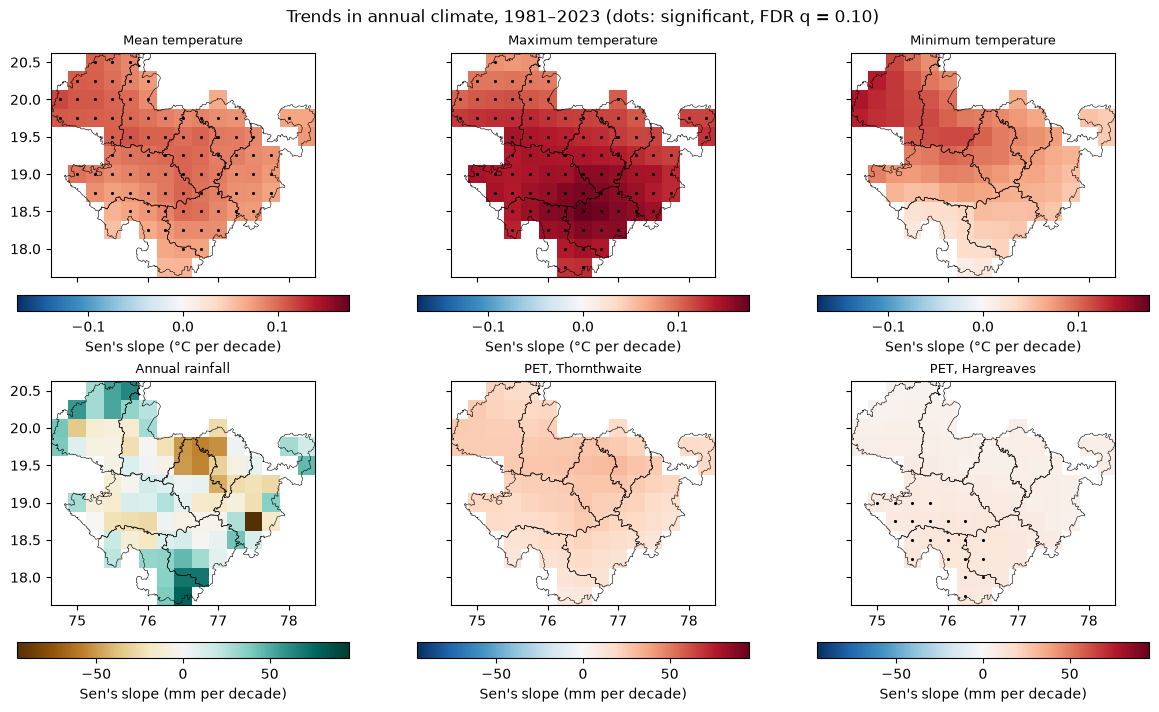

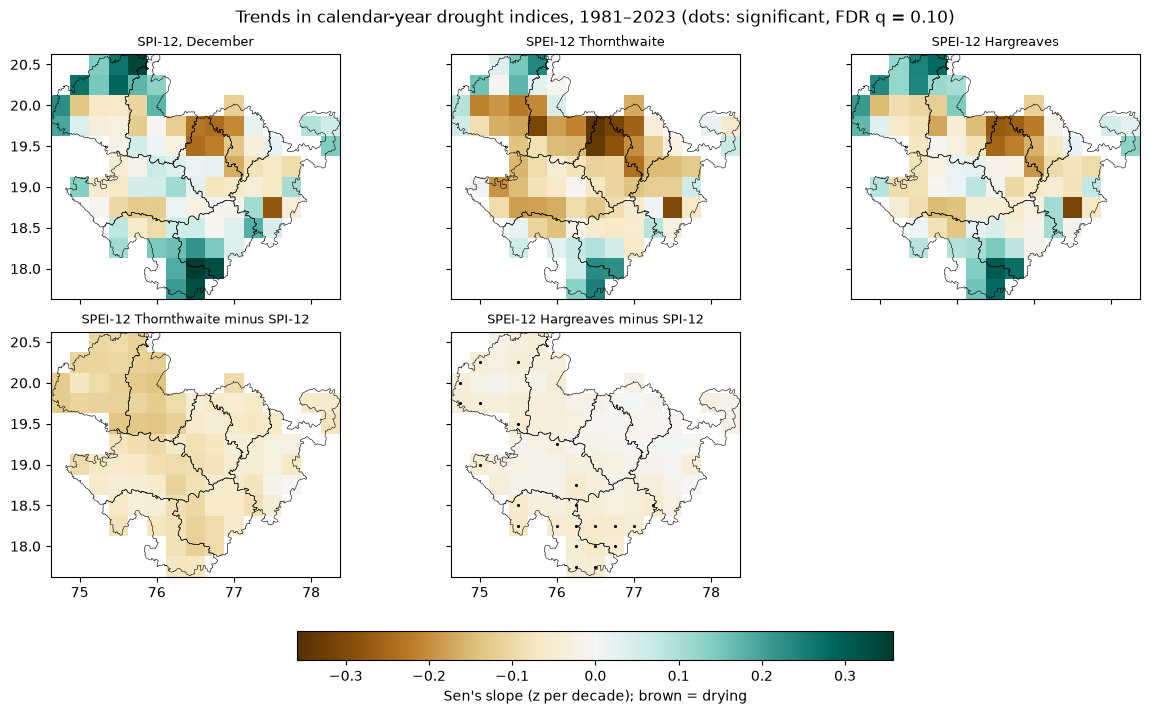

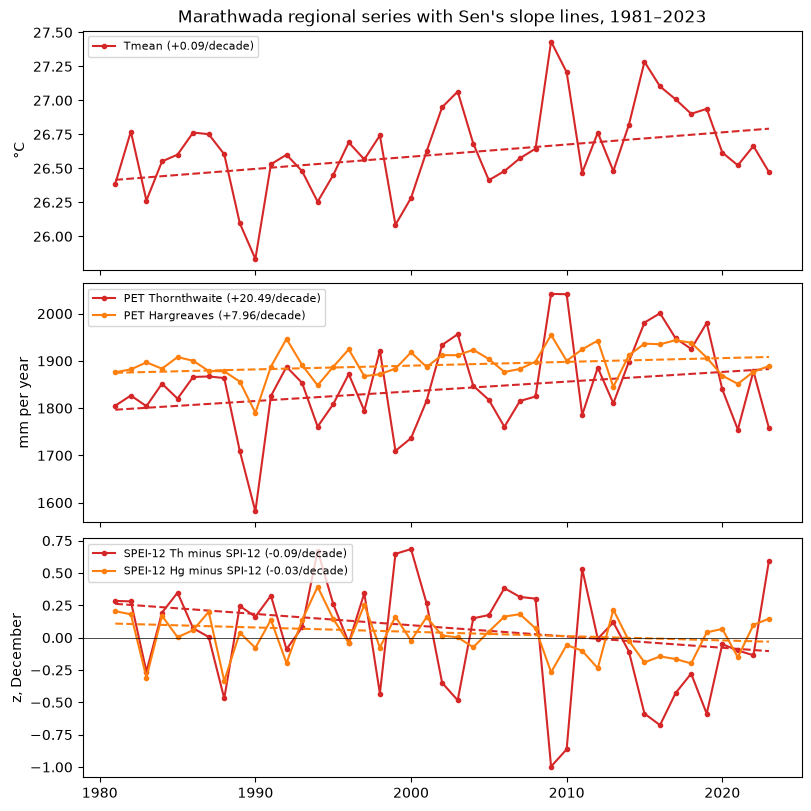

In [6]:
import geopandas as gpd
import matplotlib.pyplot as plt

districts = gpd.read_file("../data/shapefiles/marathwada_districts.gpkg")

def trend_map(ax, v, cmap, lim, title):
    """Sen's slope per decade, with dots on cells that pass FDR at q = 0.10."""
    im = (grid[v].sel(field="slope") * 10).plot(ax=ax, cmap=cmap, vmin=-lim, vmax=lim, add_colorbar=False)
    sig = tr.fdr(grid[v].sel(field="p")).stack(pt=("lat", "lon"))
    sig = sig[sig]
    ax.plot(sig.lon, sig.lat, ".", color="k", ms=2.5)
    districts.boundary.plot(ax=ax, color="k", lw=0.4)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
    return im

def lim_of(*vs):
    return 10 * max(float(abs(grid[v].sel(field="slope")).max()) for v in vs)

panels = [("tmean", "Mean temperature", "°C"), ("tmax", "Maximum temperature", "°C"),
          ("tmin", "Minimum temperature", "°C"), ("pr", "Annual rainfall", "mm"),
          ("pet_th", "PET, Thornthwaite", "mm"), ("pet_hg", "PET, Hargreaves", "mm")]
tlim, mlim = lim_of("tmean", "tmax", "tmin"), lim_of("pr", "pet_th", "pet_hg")
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True, layout="constrained")
for ax, (v, title, unit) in zip(axes.flat, panels):
    cmap = "BrBG" if v == "pr" else "RdBu_r"
    im = trend_map(ax, v, cmap, tlim if unit == "°C" else mlim, title)
    fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.85, label=f"Sen's slope ({unit} per decade)")
fig.suptitle("Trends in annual climate, 1981–2023 (dots: significant, FDR q = 0.10)")
fig.savefig("../outputs/figures/fig08_driver_trends.png", dpi=300)

panels = [("spi", "SPI-12, December"), ("spei_th", "SPEI-12 Thornthwaite"), ("spei_hg", "SPEI-12 Hargreaves"),
          ("th_minus_spi", "SPEI-12 Thornthwaite minus SPI-12"), ("hg_minus_spi", "SPEI-12 Hargreaves minus SPI-12")]
lim = lim_of(*[v for v, _ in panels])
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True, layout="constrained")
for ax, (v, title) in zip(axes.flat, panels):
    im = trend_map(ax, v, "BrBG", lim, title)
axes[1, 2].set_visible(False)
fig.colorbar(im, ax=axes, orientation="horizontal", shrink=0.5, label="Sen's slope (z per decade); brown = drying")
fig.suptitle("Trends in calendar-year drought indices, 1981–2023 (dots: significant, FDR q = 0.10)")
fig.savefig("../outputs/figures/fig09_index_trends.png", dpi=300)

def sen_line(s):
    b = tr._trend_1d(s.values)[0]
    t = s.index.values
    return np.median(s.values) + b * (t - np.median(t))

rows = [([("tmean", "Tmean")], "°C"),
        ([("pet_th", "PET Thornthwaite"), ("pet_hg", "PET Hargreaves")], "mm per year"),
        ([("th_minus_spi", "SPEI-12 Th minus SPI-12"), ("hg_minus_spi", "SPEI-12 Hg minus SPI-12")], "z, December")]
fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True, layout="constrained")
for ax, (series, ylab) in zip(axes, rows):
    for (v, lab), c in zip(series, ["tab:red", "tab:orange"]):
        ax.plot(annual.index, annual[v], "o-", ms=3, color=c, label=f"{lab} ({rt.loc[v, 'per_decade']:+.2f}/decade)")
        ax.plot(annual.index, sen_line(annual[v]), "--", color=c)
    ax.set_ylabel(ylab)
    ax.legend(fontsize=8, loc="upper left")
axes[2].axhline(0, color="k", lw=0.5)
axes[0].set_title("Marathwada regional series with Sen's slope lines, 1981–2023")
fig.savefig("../outputs/figures/fig10_regional_trends.png", dpi=300)